In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util_machine_learning as uml
import utils.visualization as vis

import test_code.dfield_approach_elastix.constants as cts
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

from scipy import stats

from tissue_based.features_loader import FeaturesLoader as FeaturesLoaderTB
from whole_brain_based.features_loader import FeaturesLoader as FeaturesLoaderWBB

np.set_printoptions(precision=4)

matching_ids = pil.get_matching_ids()
EXCLUDED_PATIENTS = pil.EXCLUDED_PATIENTS


matching_ids = [x for x in matching_ids if x not in EXCLUDED_PATIENTS]

SERVER: False


# Top similarity table

In [2]:
reader_tb_hunt3 = FeaturesLoaderTB(3, pil.get_matching_ids(), hunt=3)
reader_tb_hunt4 = FeaturesLoaderTB(3, pil.get_matching_ids(), hunt=4)
reader_wbb_hunt3 = FeaturesLoaderWBB(pil.get_matching_ids(), hunt=3)
reader_wbb_hunt4 = FeaturesLoaderWBB(pil.get_matching_ids(), hunt=4)

# sim_metrics_tb= ["dice_1", "dice_2", "dice_3"]
sim_metrics_tb= ["dice_mean"]
sim_metrics_wbb= ["ssim"]

def get_similarity_table(reader_hunt3, reader_hunt4, sim_metrics):
    similarity_table = np.zeros((len(sim_metrics), len(matching_ids), 2))
    for im, sim_metric in enumerate(sim_metrics):
        print(sim_metric)
        for i, id in enumerate(tqdm(matching_ids)):
            hunt3_sim_df = reader_hunt3.get_sorted_similarity_table(id, sim_metric, nb_images=20, exclude_ids=EXCLUDED_PATIENTS)
            hunt4_sim_df = reader_hunt4.get_sorted_similarity_table(id, sim_metric, nb_images=-1, exclude_ids=EXCLUDED_PATIENTS)

            best_id_hunt3 = hunt3_sim_df["id"].tolist()
            best_id_hunt4 = hunt4_sim_df["id"].tolist()

            similarity_table[im, i, 0] = hunt3_sim_df[sim_metric].iloc[0]
            similarity_table[im, i, 1] = hunt4_sim_df[sim_metric].iloc[best_id_hunt4.index(best_id_hunt3[0])]
    return similarity_table


similarity_table_tb = get_similarity_table(reader_tb_hunt3, reader_tb_hunt4, sim_metrics_tb)
similarity_table_wbb = get_similarity_table(reader_wbb_hunt3, reader_wbb_hunt4, sim_metrics_wbb)


# similarity_df = pd.DataFrame(similarity_table, columns=["HUNT3", "HUNT4"])



dice_mean


100%|██████████| 698/698 [00:01<00:00, 449.77it/s]


ssim


100%|██████████| 698/698 [00:01<00:00, 471.78it/s]


In [3]:
melted_cols = ["Metric", 'Similarity']
def melt_similarity_table(similarity_table, sim_metrics, melted_cols=melted_cols):
    df = pd.DataFrame(columns=melted_cols)
    for i, sim_metric in enumerate(sim_metrics):
        similarity_df = pd.DataFrame(similarity_table[i], columns=[f"{sim_metric}_HUNT3", f"{sim_metric}_HUNT4"])
        df_melted = similarity_df.melt(var_name=melted_cols[0], value_name=melted_cols[1])
        df = pd.concat([df, df_melted], ignore_index=True)
    return df

similarity_table_tb_melted = melt_similarity_table(similarity_table_tb, sim_metrics_tb)
similarity_table_wbb_melted = melt_similarity_table(similarity_table_wbb, sim_metrics_wbb)

df = pd.concat([similarity_table_wbb_melted, similarity_table_tb_melted], ignore_index=True)


C:\Users\Agustin\AppData\Local\Temp\ipykernel_25396\289339183.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, df_melted], ignore_index=True)
C:\Users\Agustin\AppData\Local\Temp\ipykernel_25396\289339183.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, df_melted], ignore_index=True)


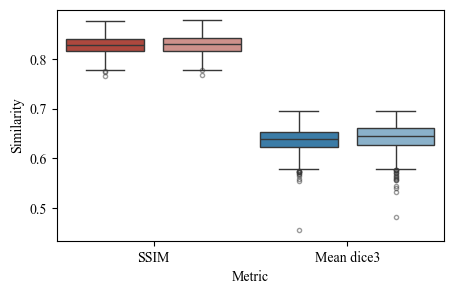

In [5]:
def dislay_boxplot_df(df, tytle="", figsize=(20, 6), palette="pastel", labels_to_display=None):
    # Crear el boxplot con jitter
    flierprops = dict(marker='o', color='black', alpha=0.5, markersize=3)

    plt.figure(figsize=figsize)
    sns.boxplot(x=melted_cols[0], y=melted_cols[1], hue=melted_cols[0], data=df, palette=palette, flierprops=flierprops)
    sns.stripplot(x=melted_cols[0], y=melted_cols[1], data=df, color='black', alpha=0.0, jitter=True, size=0.1)

    if labels_to_display:
         
        positions = np.array([i+1 for i in range(len(labels_to_display)*2)])
        positions = positions[::2] - 0.5
        plt.gca().set_xticks(positions)
        # plt.gca().set_xticks(range(len(labels_to_display)))
        plt.gca().set_xticklabels(labels_to_display)

    # Ajustar las etiquetas del eje x para mostrar solo la mitad
    # x_labels = plt.gca().get_xticklabels()
    # for i, label in enumerate(x_labels):
    #     if i % 2 != 0:  # Mostrar solo cada segunda etiqueta
    #         label.set_visible(False)

    plt.savefig(pil.get_save_image_path_name("inter_individual"), dpi=600, bbox_inches='tight')
    plt.title(tytle)
    # plt.ylim(0, 1)
    plt.show()

custom_palette = {
    'ssim_HUNT3': np.array((192, 57, 43))/255,
    'ssim_HUNT4': np.array((217, 136, 128))/255,
    'dice_1_HUNT3': np.array((86, 101, 115 ))/255,
    'dice_1_HUNT4': np.array((133, 146, 158 ))/255,
    'dice_2_HUNT3': np.array((41, 128, 185))/255,
    'dice_2_HUNT4': np.array((127, 179, 213 ))/255,
    'dice_3_HUNT3': np.array((22, 160, 133))/255,
    'dice_3_HUNT4': np.array((130, 224, 170))/255,

    'dice_mean_HUNT3': np.array((41, 128, 185))/255,
    'dice_mean_HUNT4': np.array((127, 179, 213 ))/255,
}

from matplotlib import rcParams

# Configurar Matplotlib para usar Times New Roman
rcParams['font.family'] = 'serif'
rcParams['font.serif'] = ['Times New Roman'] + rcParams['font.serif']

# dislay_boxplot_df(df, tytle="Best patient similarity", melted=True, figsize=(5, 3), palette=custom_palette)
# labels_to_display = ["SSIM", "", "dice CSF", "", "dice GM", "", "dice WM", ""]
# labels_to_display = ["SSIM", "dice CSF", "dice GM", "dice WM"]
labels_to_display = ["SSIM", "Mean dice3"]
dislay_boxplot_df(df, tytle="", figsize=(5, 3), labels_to_display=labels_to_display, palette=custom_palette)
